# 1. Library Imports

In [53]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve, auc,
                        roc_curve, accuracy_score, precision_score, roc_auc_score, recall_score, f1_score, precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer



# 2. Data Loading

In [2]:
df = pd.read_csv("Data/AIML Dataset.csv")

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.drop(columns="step", inplace= True)


In [5]:
df_model = df.drop(["nameOrig", "nameDest", "isFlaggedFraud"], axis=1)

In [6]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [7]:
df["DiffbalanceOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["DiffbalanceDest"] = df["oldbalanceDest"] - df["newbalanceDest"]

In [8]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,DiffbalanceOrig,DiffbalanceDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [9]:
df[df["DiffbalanceOrig"] < 0].value_counts().sum()

np.int64(1399253)

In [10]:
y= df_model['isFraud']
X= df_model.drop(columns="isFraud")

In [11]:
numerical_columns = X.select_dtypes(["int64", "float64"]).columns
numerical_columns

Index(['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest'],
      dtype='str')

In [12]:
categorical_columns = X.select_dtypes("str").columns
categorical_columns

Index(['type'], dtype='str')

In [13]:
X_train , X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, stratify=y)


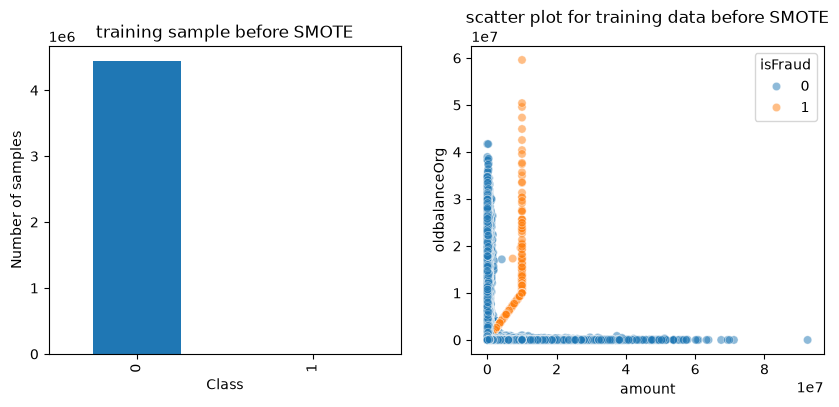

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

y_train.value_counts().plot(kind='bar', ax=axes[0], label=["0","1"])
axes[0].set_title("training sample before SMOTE")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of samples")


sns.scatterplot(
    x=X_train["amount"],
    y=X_train["oldbalanceOrg"],
    hue=y_train,
    ax=axes[1],
    alpha=0.5,
    
)

axes[1].set_title("scatter plot for training data before SMOTE")
axes[1].set_xlabel("amount")
axes[1].set_ylabel("oldbalanceOrg")


plt.show()

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(drop="first"), categorical_columns)
    ],
    remainder="drop"
)

In [16]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 3. Data Processing

In [22]:
# Handling Imbalanced Data 
def Handel_imbalanced_data(X_train, y_train):
    print("Original Train Distribution", Counter(y_train))
    
    # Under Sampling technique
    print("Applying Random Under-Sampling")
    rus = RandomUnderSampler(sampling_strategy=1, random_state=42)
    x_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
    print("Distribution after Under Sampling", Counter(y_train_rus))

    # SMOTE over Sampling technique
    print("Applying SMOTE")
    smote = SMOTE(sampling_strategy=0.1,random_state=42)
    x_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
    print("Distribution after Under Sampling", Counter(y_train_smote))

    # Combine Undersampling with SMOTE
    print("Applying Under-sampling with SMOTE")
    rus_smote = RandomUnderSampler(sampling_strategy=0.5, random_state=42)
    X_train_rus_smote, y_train_rus_smote = rus_smote.fit_resample(x_train_smote, y_train_smote)
    print("Distribution after Under Sampling", Counter(y_train_rus_smote))

    return {
        "original" : (X_train, y_train),
        "UnderSampling" : (x_train_rus, y_train_rus),
        "OverSampling" : (x_train_smote, y_train_smote),
        "combine" : (X_train_rus_smote, y_train_rus_smote)
    }
    

# 4. Training and evaluation 

In [43]:
def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    """
    Fonction pour évaluer les performances d'un modèle
    """
    # Prédictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Probabilités pour ROC-AUC
    if hasattr(model, 'predict_proba'):
        y_pred_proba = model.predict_proba(X_test)[:, 1]
        # Calculer l'aire sous la courbe auc
        roc_auc = roc_auc_score(y_test, y_pred_proba)
    else:
        roc_auc = None



    # Affichage
    print(f"\n{'='*80}")
    print(f"MODÈLE: {name}")
    print(f"{'='*80}")

    # Matrice de confusion
    print("="*80)
    print("Confusion matrix computed !")
    cm = confusion_matrix(y_test, y_pred_test)

    # Classification Report
    cf_report = classification_report(y_test, y_pred_test,
                                target_names=['Resté', 'Parti'])
    print(cf_report)


    # Compute the ROC - AUC 
    fpr,tpr,_ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    print("ROC - AUC computed")

    # compute the PR - AUC 
    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    pr_auc = auc(recall, precision)
    print("PR - AUC computed")

    # Visualization 
    fig, axs = plt.subplots(
        3, 1, sharex=False, sharey=False, squeeze=False, figsize=(7,10) 
    )

    # Visualize the confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt=".0f",
        cmap='coolwarm',
        linecolor="black",
        linewidths=0.5,
        ax=axs[0, 0]
    )
    axs[0, 0].set_title("confusion matrix")
    axs[0, 0].set_xlabel("prediction")
    axs[0, 0].set_title("true")

    # Visualize the ROC - AUC 
    axs[1,0].plot(
        fpr,
        tpr,
        label="ROC - AUC Curve",
        color="green",
        linewidth=2
    )

    axs[1,0].set_title("ROC-AUC Curve")
    axs[1,0].set_xlabel("FPR")
    axs[1,0].set_ylabel("TPR")
    axs[1,0].grid()
    axs[1,0].legend(loc="lower right")
    
    # Visualize the PR - AUC 
    axs[2,0].plot(
        precision,
        recall,
        label="PR - AUC Curve",
        color="blue",
        linewidth=2
    )

    axs[2,0].set_title("PR-AUC Curve")
    axs[2,0].set_xlabel("PRECISION")
    axs[2,0].set_ylabel("RECALL")
    axs[2,0].grid()
    axs[2,0].legend(loc="lower left")    

    fig.suptitle(
        f"MODEL EVALUATION & VISUALIZATION {name.upper()}"
    )

    plt.tight_layout()
    plt.show()

        # Métriques
    results = {
        'Modèle': name,
        'Accuracy Train': accuracy_score(y_train, y_pred_train),
        'Accuracy Test': accuracy_score(y_test, y_pred_test),
        'Precision': precision_score(y_test, y_pred_test),
        'Recall': recall_score(y_test, y_pred_test),
        'F1-Score': f1_score(y_test, y_pred_test),
        'ROC-AUC': roc_auc,
        'PR-AUC' : pr_auc
    }

    for metric, value in results.items():
        if metric != 'Modèle':
            if value is not None:
                print(f"{metric:20s}: {value:.4f}")
            else:
                print(f"{metric:20s}: N/A")

    return results

# 5. Model training and evaluation practice

In [26]:
# Une fonction qui prend les different type de resampling et le model dont on va faire le training 
# (le modele perndra les hyperparamétres par defaut)

def train_and_evaluate_model(resampled_data, model_dict, X_test, y_test):
    # resampled_data : est le resultat de Handel_imbalanced_data()
    # model_dict : contient { name : model_name, model_instance : model}
    resampling_method = ["original", "UnderSampling", "OverSampling", "combine"]
    model = model_dict["model_instance"]
    #Les resultat du modele sur les methodes 
    resultats = []

    for methode in resampling_method:
        print("="*80)
        print("Training ", model_dict["name"].upper(), "avec la méthode : ", methode.upper())
        X_train_resample, y_train_resample = resampled_data[methode]

        # Train the model
        model.fit(X_train_resample, y_train_resample)

        # Evaluate the model
        resultat = evaluate_model(model_dict["name"], model_dict["model_instance"], X_train_resample, X_test, y_train_resample, y_test)
        resultat["methode"] = methode
        resultats.append(resultat)
    return resultats

# 6. Best Resampling Method Selection 

In [20]:
# Aprés avoir tous les listes contenant les resultats de chaque modèle en utilisant les differents méthodes on crée
# la liste resultats_modeles qui contient tous les resultats   
def select_best_methode(resultats_modeles):

    # Puisque les données sont désequilibrées alors le choix du meilleur modéle se fait par la metrice "pr-auc"
    print("Selecting the best model and sampling method")
    best_pr_auc = -np.inf
    best_method = None
    best_model = None

    for resultat in resultats_modeles:
        if(resultat['PR-AUC']> best_pr_auc):
            best_method = resultat["methode"]
            best_model = resultat["Modèle"]

    print(f"The best model is : {best_model}\n The best method of resampling is : {best_method}")


# 7. Runing models and Visualizing the results 

## Logistic Regression Model

Original Train Distribution Counter({0: 4448085, 1: 5749})
Applying Random Under-Sampling
Distribution after Under Sampling Counter({0: 5749, 1: 5749})
Applying SMOTE
Distribution after Under Sampling Counter({0: 4448085, 1: 444808})
Applying Under-sampling with SMOTE
Distribution after Under Sampling Counter({0: 889616, 1: 444808})
Training  LOGISTIC REGRESSION avec la méthode :  ORIGINAL

MODÈLE: Logistic Regression
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.90      0.39      0.55      2464

    accuracy                           1.00   1908786
   macro avg       0.95      0.70      0.77   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


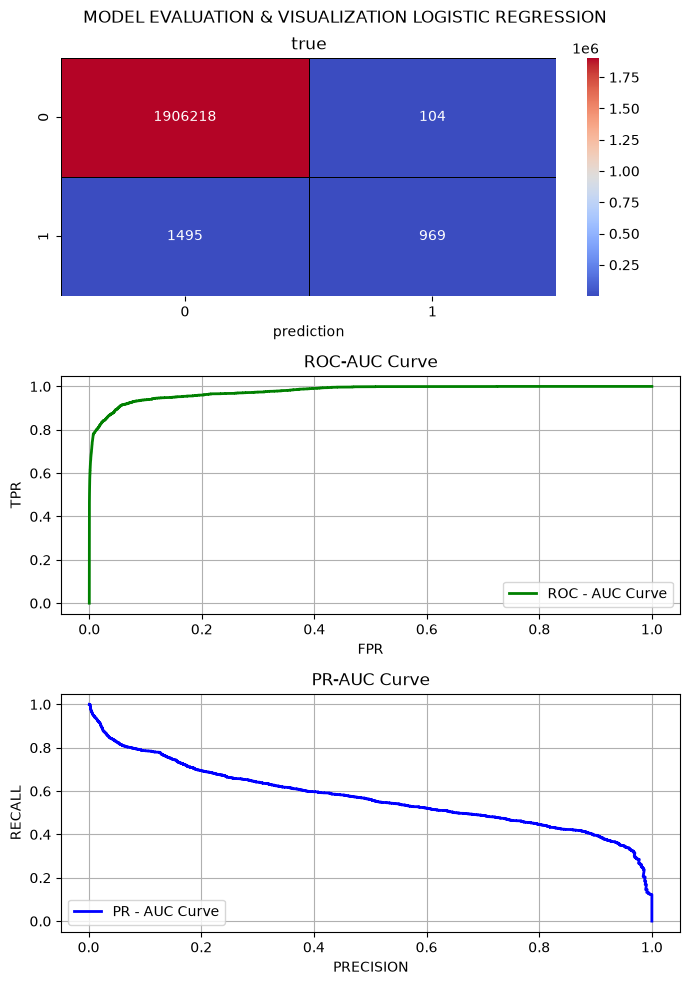

Accuracy Train      : 0.9992
Accuracy Test       : 0.9992
Precision           : 0.9031
Recall              : 0.3933
F1-Score            : 0.5479
ROC-AUC             : 0.9768
PR-AUC              : 0.5706
Training  LOGISTIC REGRESSION avec la méthode :  UNDERSAMPLING

MODÈLE: Logistic Regression
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.94      0.97   1906322
       Parti       0.02      0.89      0.04      2464

    accuracy                           0.94   1908786
   macro avg       0.51      0.91      0.50   1908786
weighted avg       1.00      0.94      0.97   1908786

ROC - AUC computed
PR - AUC computed


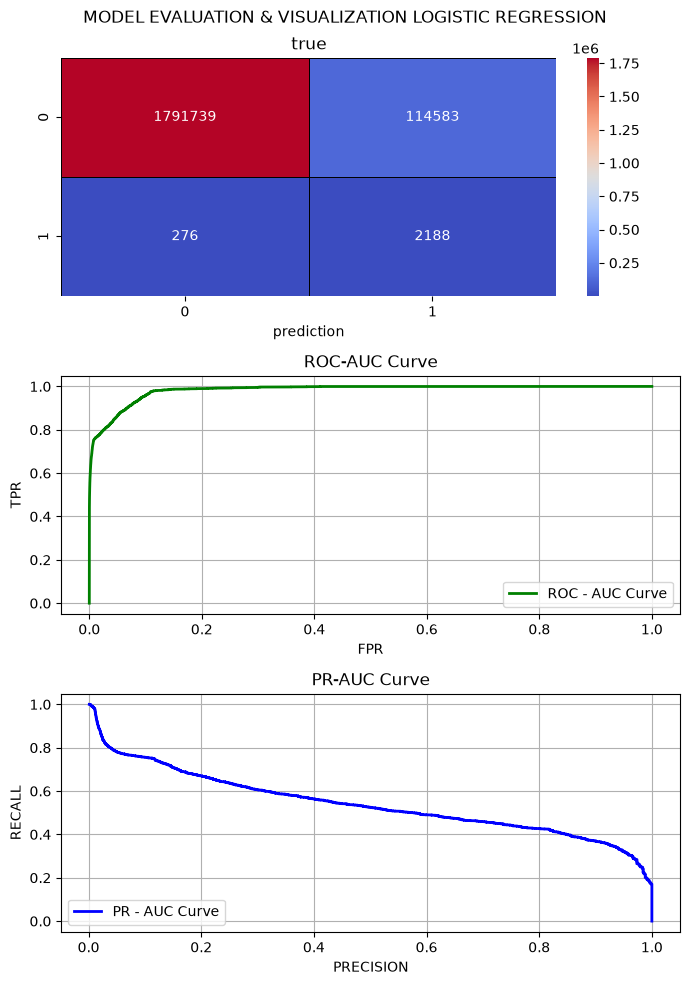

Accuracy Train      : 0.9165
Accuracy Test       : 0.9398
Precision           : 0.0187
Recall              : 0.8880
F1-Score            : 0.0367
ROC-AUC             : 0.9822
PR-AUC              : 0.5422
Training  LOGISTIC REGRESSION avec la méthode :  OVERSAMPLING

MODÈLE: Logistic Regression
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.99      1.00   1906322
       Parti       0.16      0.78      0.27      2464

    accuracy                           0.99   1908786
   macro avg       0.58      0.89      0.63   1908786
weighted avg       1.00      0.99      1.00   1908786

ROC - AUC computed
PR - AUC computed


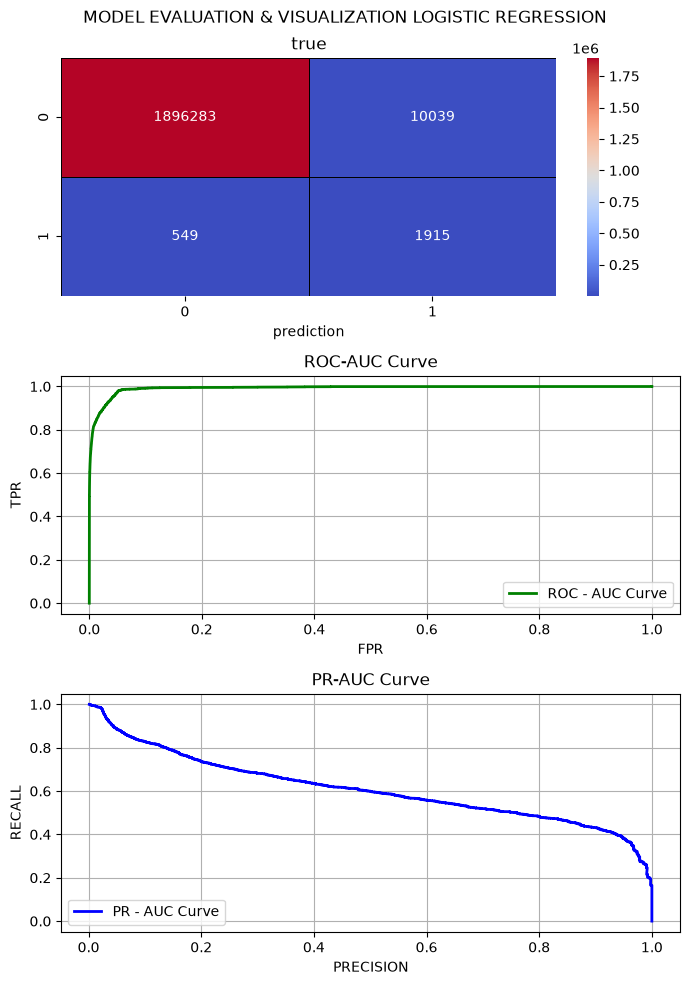

Accuracy Train      : 0.9762
Accuracy Test       : 0.9945
Precision           : 0.1602
Recall              : 0.7772
F1-Score            : 0.2656
ROC-AUC             : 0.9917
PR-AUC              : 0.6102
Training  LOGISTIC REGRESSION avec la méthode :  COMBINE

MODÈLE: Logistic Regression
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.97      0.98   1906322
       Parti       0.04      0.89      0.07      2464

    accuracy                           0.97   1908786
   macro avg       0.52      0.93      0.53   1908786
weighted avg       1.00      0.97      0.98   1908786

ROC - AUC computed
PR - AUC computed


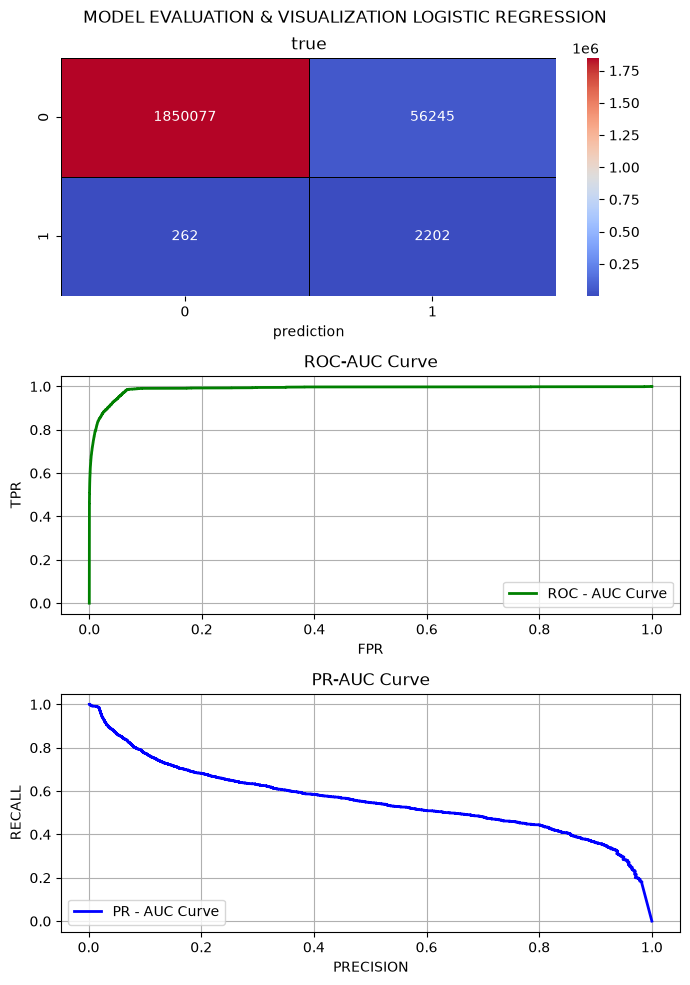

Accuracy Train      : 0.9471
Accuracy Test       : 0.9704
Precision           : 0.0377
Recall              : 0.8937
F1-Score            : 0.0723
ROC-AUC             : 0.9885
PR-AUC              : 0.5571


In [44]:
resampled_data = Handel_imbalanced_data(X_train_processed, y_train)
LR_model = LogisticRegression(max_iter=1000, random_state=42)
model_dict = {"name" : "Logistic Regression", "model_instance": LR_model}

# Les resultats du modèle
resultats_LR = train_and_evaluate_model(resampled_data, model_dict, X_test_processed, y_test)

## Random Forest Model

Training  RANDOMFORESTCLASSIFIER avec la méthode :  ORIGINAL

MODÈLE: RandomForestClassifier
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.99      0.71      0.83      2464

    accuracy                           1.00   1908786
   macro avg       0.99      0.85      0.91   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


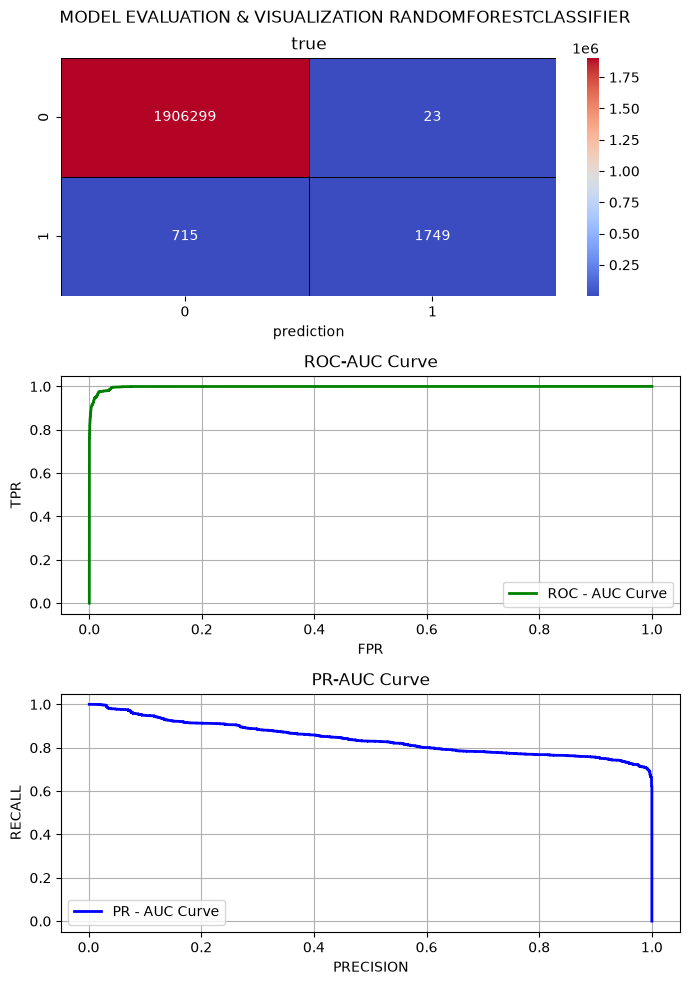

Accuracy Train      : 0.9996
Accuracy Test       : 0.9996
Precision           : 0.9870
Recall              : 0.7098
F1-Score            : 0.8258
ROC-AUC             : 0.9981
PR-AUC              : 0.8399
Training  RANDOMFORESTCLASSIFIER avec la méthode :  UNDERSAMPLING

MODÈLE: RandomForestClassifier
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.98      0.99   1906322
       Parti       0.07      1.00      0.13      2464

    accuracy                           0.98   1908786
   macro avg       0.54      0.99      0.56   1908786
weighted avg       1.00      0.98      0.99   1908786

ROC - AUC computed
PR - AUC computed


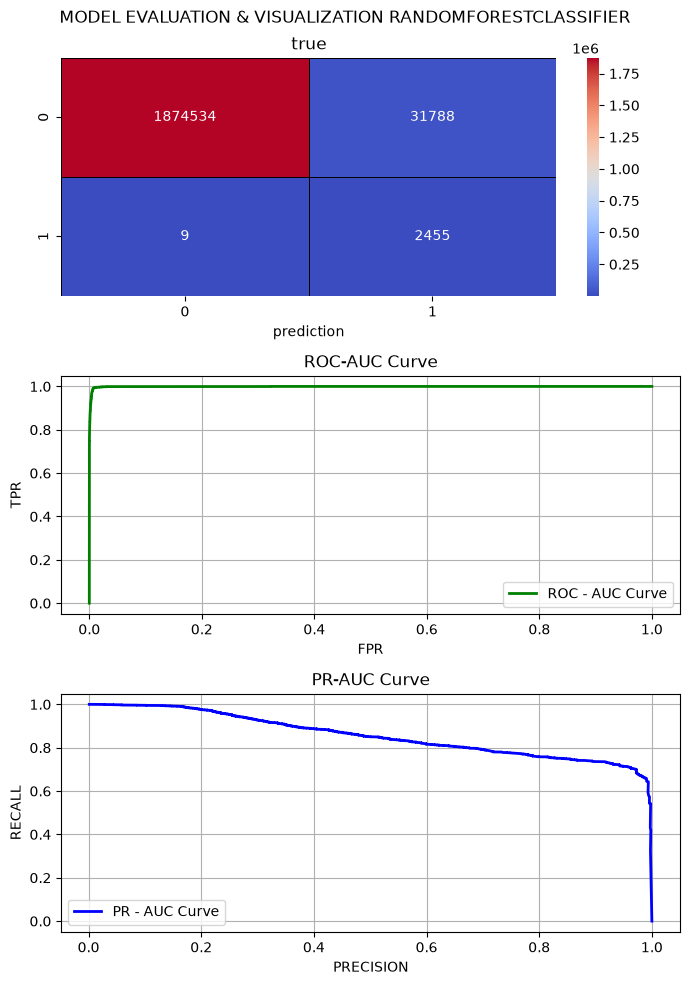

Accuracy Train      : 0.9930
Accuracy Test       : 0.9833
Precision           : 0.0717
Recall              : 0.9963
F1-Score            : 0.1338
ROC-AUC             : 0.9993
PR-AUC              : 0.8571
Training  RANDOMFORESTCLASSIFIER avec la méthode :  OVERSAMPLING

MODÈLE: RandomForestClassifier
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.42      0.90      0.57      2464

    accuracy                           1.00   1908786
   macro avg       0.71      0.95      0.79   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


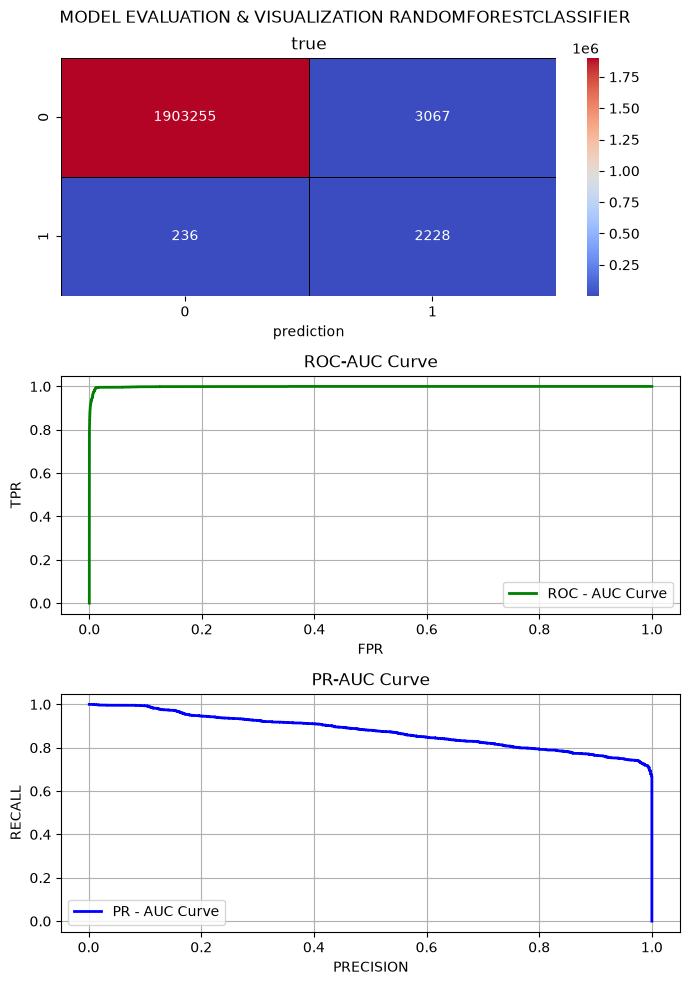

Accuracy Train      : 0.9918
Accuracy Test       : 0.9983
Precision           : 0.4208
Recall              : 0.9042
F1-Score            : 0.5743
ROC-AUC             : 0.9989
PR-AUC              : 0.8745
Training  RANDOMFORESTCLASSIFIER avec la méthode :  COMBINE

MODÈLE: RandomForestClassifier
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.99      0.99   1906322
       Parti       0.10      0.99      0.18      2464

    accuracy                           0.99   1908786
   macro avg       0.55      0.99      0.59   1908786
weighted avg       1.00      0.99      0.99   1908786

ROC - AUC computed
PR - AUC computed


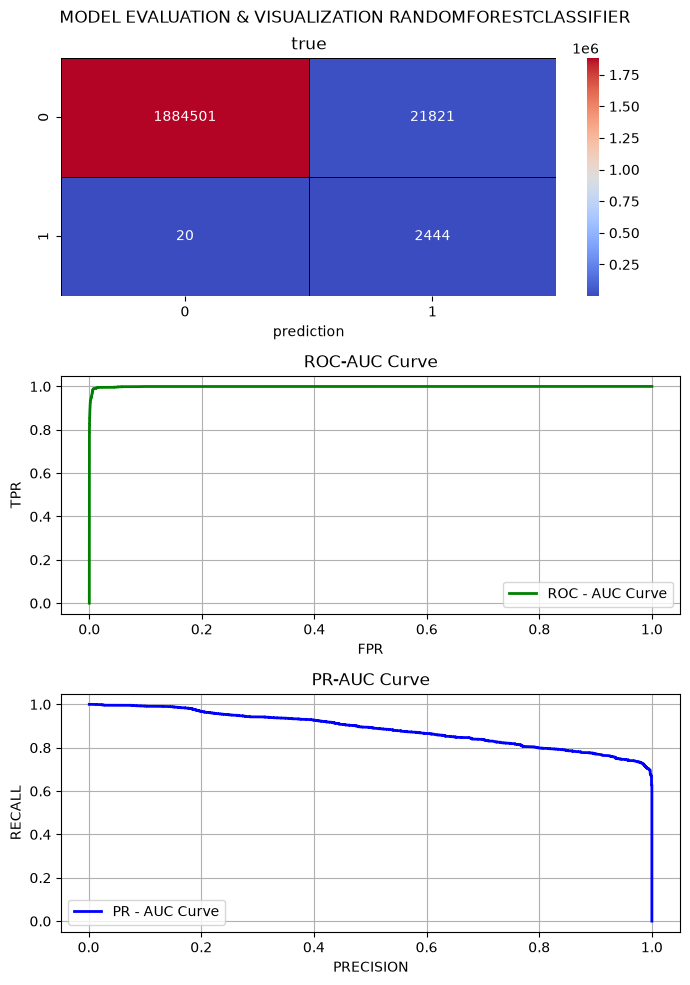

Accuracy Train      : 0.9914
Accuracy Test       : 0.9886
Precision           : 0.1007
Recall              : 0.9919
F1-Score            : 0.1829
ROC-AUC             : 0.9992
PR-AUC              : 0.8856


In [45]:
RF_model = RandomForestClassifier(n_estimators=100,max_depth=10, min_samples_split=5 ,random_state=42)
model_dict_RF = {"name" : "RandomForestClassifier", "model_instance": RF_model}

# Les resultats du modèle
resultats_RF = train_and_evaluate_model(resampled_data, model_dict_RF, X_test_processed, y_test)

## XGBoost Model

Training  XGBOOST avec la méthode :  ORIGINAL


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:00:12] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



MODÈLE: XGBoost
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.53      0.50      0.51      2464

    accuracy                           1.00   1908786
   macro avg       0.76      0.75      0.76   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


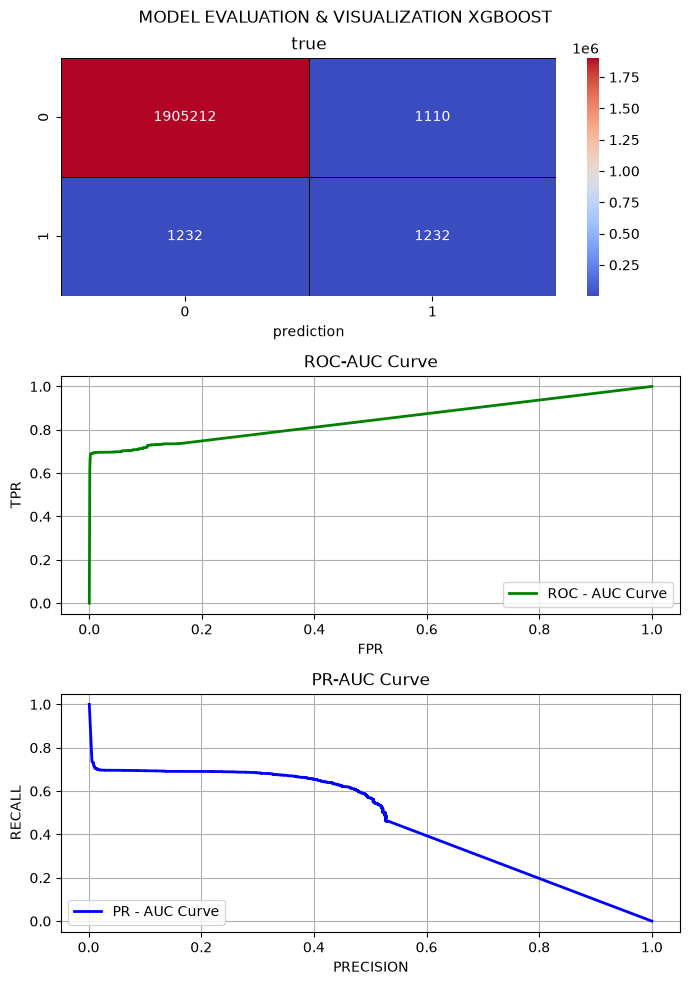

Accuracy Train      : 0.9988
Accuracy Test       : 0.9988
Precision           : 0.5260
Recall              : 0.5000
F1-Score            : 0.5127
ROC-AUC             : 0.8429
PR-AUC              : 0.4628
Training  XGBOOST avec la méthode :  UNDERSAMPLING


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:00:18] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



MODÈLE: XGBoost
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      0.99      1.00   1906322
       Parti       0.12      1.00      0.22      2464

    accuracy                           0.99   1908786
   macro avg       0.56      0.99      0.61   1908786
weighted avg       1.00      0.99      0.99   1908786

ROC - AUC computed
PR - AUC computed


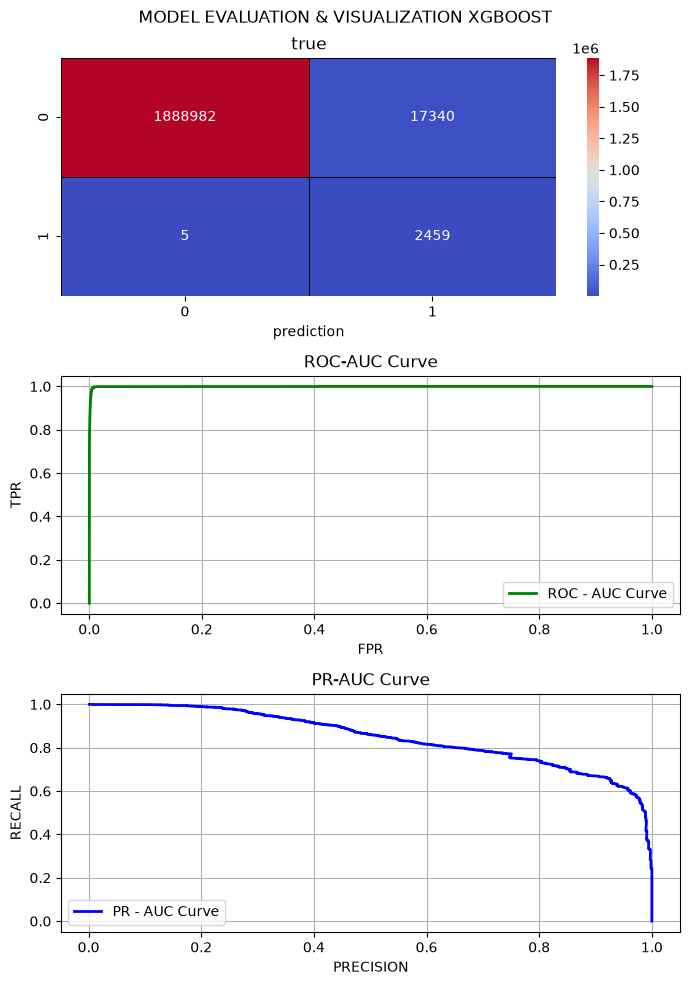

Accuracy Train      : 0.9999
Accuracy Test       : 0.9909
Precision           : 0.1242
Recall              : 0.9980
F1-Score            : 0.2209
ROC-AUC             : 0.9993
PR-AUC              : 0.8486
Training  XGBOOST avec la méthode :  OVERSAMPLING


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:00:20] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



MODÈLE: XGBoost
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.61      0.98      0.75      2464

    accuracy                           1.00   1908786
   macro avg       0.80      0.99      0.87   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


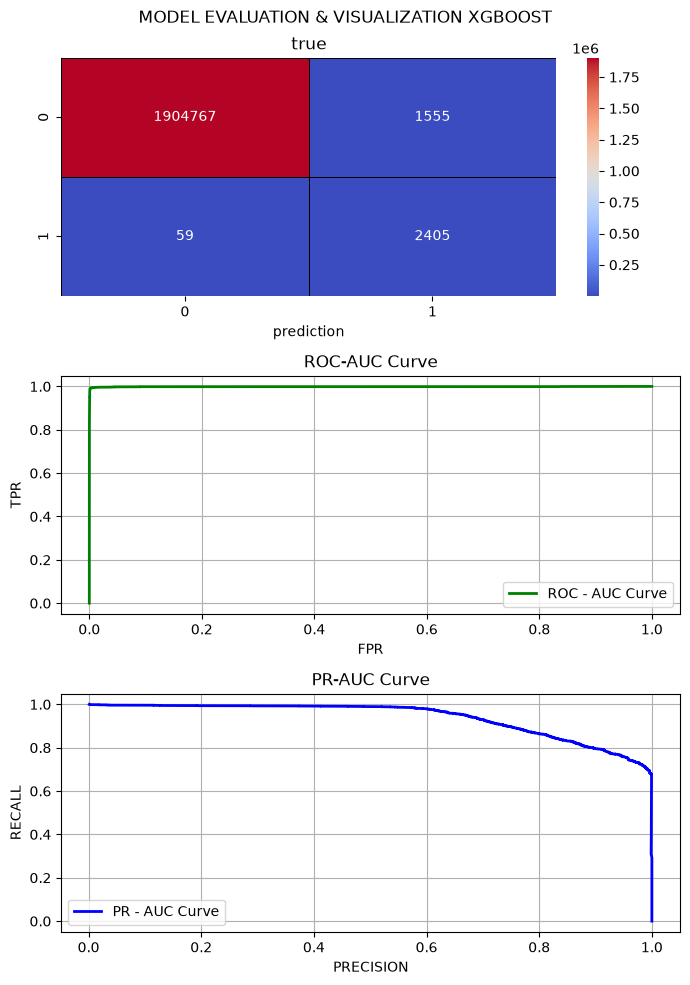

Accuracy Train      : 0.9992
Accuracy Test       : 0.9992
Precision           : 0.6073
Recall              : 0.9761
F1-Score            : 0.7488
ROC-AUC             : 0.9987
PR-AUC              : 0.9387
Training  XGBOOST avec la méthode :  COMBINE


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:00:27] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



MODÈLE: XGBoost
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.47      0.99      0.63      2464

    accuracy                           1.00   1908786
   macro avg       0.73      1.00      0.82   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


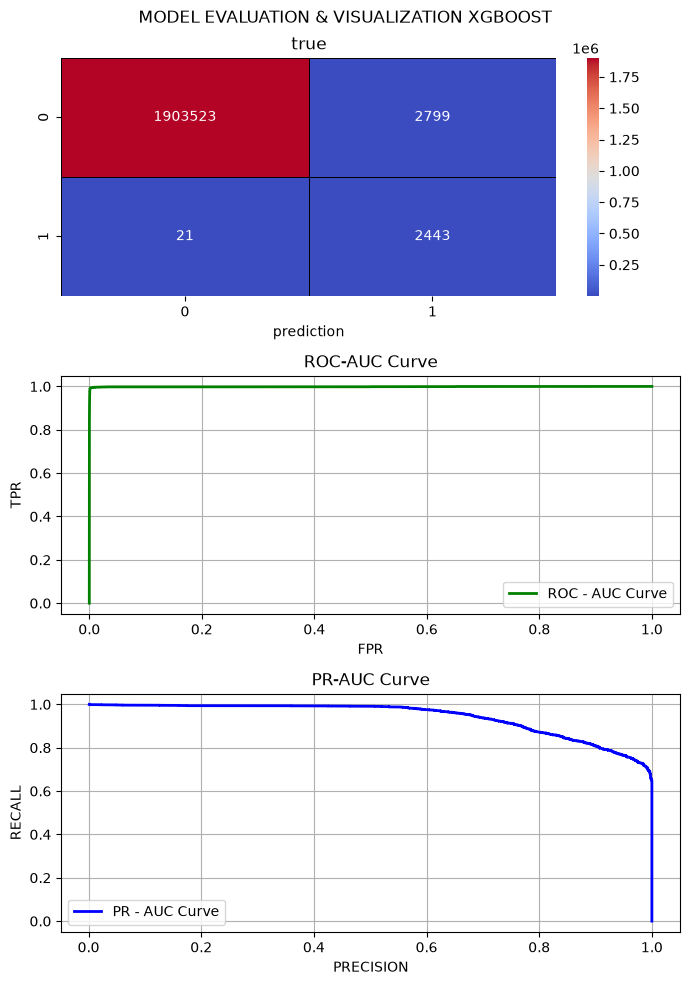

Accuracy Train      : 0.9991
Accuracy Test       : 0.9985
Precision           : 0.4660
Recall              : 0.9915
F1-Score            : 0.6341
ROC-AUC             : 0.9988
PR-AUC              : 0.9428


In [ ]:
XGB_model = xgb.XGBClassifier(n_estimators=100,max_depth=10,random_state=42)
model_dict_XGB = {"name" : "XGBoost", "model_instance": XGB_model}

# Les resultats du modèle
resultats_XGB = train_and_evaluate_model(resampled_data, model_dict_XGB, X_test_processed, y_test)

In [50]:
resultats_modeles = []
resultats_modeles.extend(resultats_LR)
resultats_modeles.extend(resultats_RF)
resultats_modeles.extend(resultats_XGB)

## Résultat du meilleur modèle et méthode 

In [51]:
select_best_methode(resultats_modeles)

Selecting the best model and sampling method
The best model is : XGBoost
 The best method of resampling is : combine


# Best Model Optimization (XGBoost + Combined method)

In [ ]:
# intialisation du modèle
best_model = xgb.XGBClassifier(random_state=42)

# La méthode de resampling 
X_train_best_method, y_train_best_method = resampled_data["combine"]

# StratifiedKFold pour presever la distribution des classes 
skf = StratifiedKFold(n_splits=7, shuffle=True, random_state=42)

# Definir les hyperparamétres
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "min_child_weight": [1, 3],
    "subsample": [0.8, 1.0]
}

# evaluer les hyperparamétres combinés en utilisant GridSearchCV
grid = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    cv=skf,
    # the scoring strategy used is related to the PR curve 
    scoring='average_precision'
)

grid.fit(X_train_best_method, y_train_best_method)

print("Best model params : ", grid.best_params_)
print("Best Score : ", grid.best_score_)

best_model_choosen = grid.best_estimator_

# The final predictions of the best model
y_pred = best_model_choosen.predict(X_test_processed)
y_prob = best_model_choosen.predict_proba(X_test_processed)[:,1]



Best model params :  {'learning_rate': 0.1, 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 200, 'subsample': 0.8}
Best Score :  0.9998347752372126


ValueError: Found input variables with inconsistent numbers of samples: [4453834, 1908786]


MODÈLE: Fine Tuned XGBoost
Confusion matrix computed !
              precision    recall  f1-score   support

       Resté       1.00      1.00      1.00   1906322
       Parti       0.37      0.99      0.54      2464

    accuracy                           1.00   1908786
   macro avg       0.68      1.00      0.77   1908786
weighted avg       1.00      1.00      1.00   1908786

ROC - AUC computed
PR - AUC computed


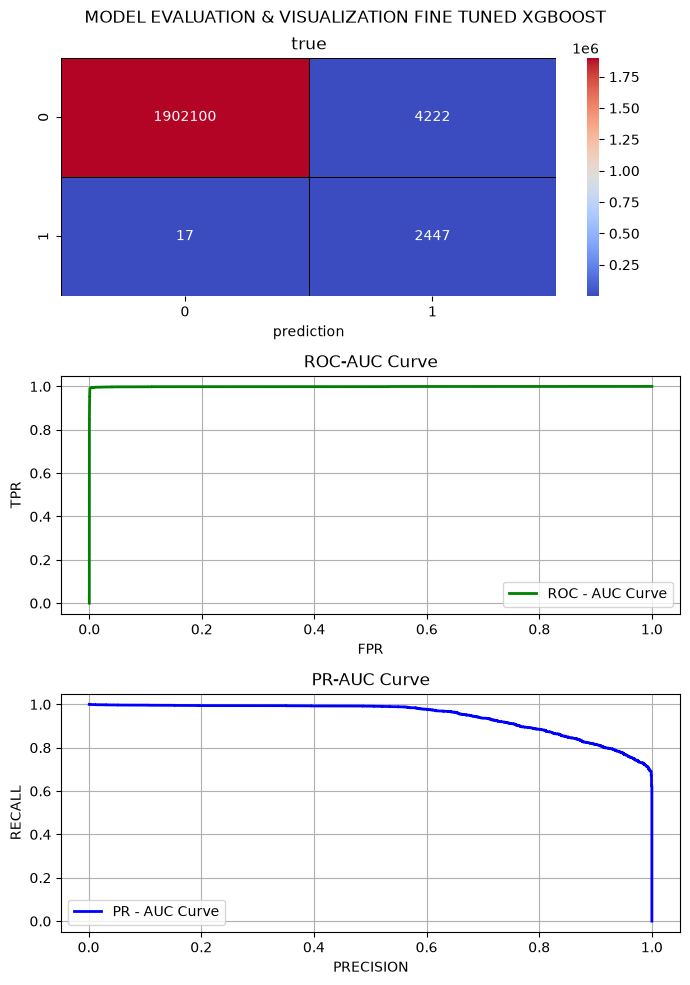

Accuracy Train      : 0.9981
Accuracy Test       : 0.9978
Precision           : 0.3669
Recall              : 0.9931
F1-Score            : 0.5359
ROC-AUC             : 0.9992
PR-AUC              : 0.9445


{'Modèle': 'Fine Tuned XGBoost',
 'Accuracy Train': 0.9980560901182832,
 'Accuracy Test': 0.9977792167377589,
 'Precision': 0.3669215774478932,
 'Recall': 0.9931006493506493,
 'F1-Score': 0.5358589729552173,
 'ROC-AUC': 0.9991626719286137,
 'PR-AUC': 0.944525836346441}

In [ ]:
result = evaluate_model("Fine Tuned XGBoost", best_model_choosen, X_train_best_method, X_test_processed, y_train_best_method, y_test)